# CS 725 · Hinglish sentiment · First baseline

This notebook gets the data and runs the first baseline (TF-IDF + Logistic Regression on raw text).

**Goal for today:** all four of us run this and get **the same macro-F1**. If we do, the data, splits and scoring are consistent and everything we build later is comparable.

* Works on Colab or Kaggle. No GPU is needed for this notebook.
* On Kaggle, turn **Internet on** (Settings → Internet) so the data can download.

## 1. Get the code
Finds the project folder if you already have it (local run). Clones only if it isn't there yet (Colab/Kaggle). Safe to re-run: it never creates a new folder twice.

In [ ]:
import os
from pathlib import Path

LOCAL = Path("/Users/kartheek/Desktop/IITB Files/FML/cs725-hinglish-sentiment")   # your laptop
COLAB = Path("/content/Hinglish-sentiment-analysis/cs725-hinglish-sentiment")    # Google Colab

if LOCAL.exists():
    os.chdir(LOCAL)
else:
    if not COLAB.exists():
        !git clone -q https://github.com/Kartheek-pallem/Hinglish-sentiment-analysis.git /content/Hinglish-sentiment-analysis
    os.chdir(COLAB)

print("Working in:", Path.cwd())

Cloning into '/home/cyno/Hinglish-sentiment-analysis'...


Working in: /home/cyno/Hinglish-sentiment-analysis/cs725-hinglish-sentiment


In [4]:
%pip install -q -r requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
Note: you may need to restart the kernel to use updated packages.


## 2. Download SentiMix and build the CSVs
Expect 14,000 / 3,000 / 3,000 tweets and **ALL CHECKS PASSED** at the end. If any check needs a look, post the output in the group chat.

In [3]:
!python3 -m src.data

train_14k_split_conll.txt: 3.44MB [00:00, 40.4MB/s]
dev_3k_split_conll.txt: 740kB [00:00, 74.5MB/s]
Hindi_test_unalbelled_conll_updated.txt: 726kB [00:00, 17.9MB/s]
test_labels_hinglish.txt: 43.2kB [00:00, 20.7MB/s]
Parsing and checking ...
  [train_14k_split_conll.txt] empty token skipped: 32
  [dev_3k_split_conll.txt] empty token skipped: 2
  [Hindi_test_unalbelled_conll_updated.txt] empty token skipped: 4
  test: 0 tweets without a label, 0 labels without a tweet
  train:  14000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.331, 'negative': 0.293}
  val  :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.327, 'negative': 0.297}
  test :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.367, 'positive': 0.333, 'negative': 0.3}
  word tags: 522563 tokens; share by tag: {'Hin': 0.465, 'Eng': 0.332, 'O': 0.202, '

## 3. Check the code works

In [4]:
!python3 -m unittest discover -s tests

  [train_14k_split_conll.txt] empty token skipped: 1
  [train_14k_split_conll.txt] missing or unknown tag set to O: 1
  [dev_3k_split_conll.txt] empty token skipped: 1
  [dev_3k_split_conll.txt] missing or unknown tag set to O: 1
  test: 0 tweets without a label, 0 labels without a tweet
  train:      3 tweets (EXPECTED 14000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  val  :      3 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  test :      2 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.5, 'negative': 0.5}
  word tags: 34 tokens; share by tag: {'Hin': 0.471, 'Eng': 0.353, 'O': 0.118, 'EMT': 0.059}
  SOME CHECKS NEED A LOOK (see above)
.../Users/kartheek/Library/Python/3.9/lib/python/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecation

## 4. Run the baseline
Set `OWNER` to your own person number (person1 … person4).

In [ ]:
OWNER = "person1"   # <- Mahesh
!python3 scripts/baseline_lr.py --owner $OWNER

train 14000 tweets, 42618 features (word)
person1_logreg_sentimix-val_raw_word: macro-F1 0.6167 | accuracy 0.6127 | F1 neg/neu/pos 0.644/0.534/0.672
person1_logreg_sentimix-test_raw_word: macro-F1 0.6762 | accuracy 0.6720 | F1 neg/neu/pos 0.695/0.594/0.740


In [ ]:
!python3 scripts/svm.py --owner person2 # first run: default C = 1  <-Manikanta

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-test_raw_word: macro-F1 0.6396 | accuracy 0.6357 | F1 neg/neu/pos 0.666/0.548/0.704


In [11]:
!python3 scripts/svm.py --owner person2 --tune # pick C on validation, then test once

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.5811 | accuracy 0.5777 | F1 neg/neu/pos 0.565/0.528/0.650
person2_svm_sentimix-val_raw_word: macro-F1 0.6033 | accuracy 0.5997 | F1 neg/neu/pos 0.621/0.517/0.672
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-val_raw_word: macro-F1 0.6110 | accuracy 0.6073 | F1 neg/neu/pos 0.647/0.520/0.666
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-val_raw_word: macro-F1 0.5838 | accuracy 0.5797 | F1 neg/neu/pos 0.623/0.502/0.626
best C on validation: 0.1 (macro-F1 0.6121)
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-test_raw_word: macro-F1 0.6765 | accuracy 0.6730 | F1 neg/neu/pos 0.701/0.587/0.742


In [12]:
!python3 scripts/svm.py --owner person2 --tune --features char # character n-grams

train 14000 tweets, 122301 features (char, raw)
person2_svm_sentimix-val_raw_char: macro-F1 0.6040 | accuracy 0.6007 | F1 neg/neu/pos 0.594/0.559/0.659
person2_svm_sentimix-val_raw_char: macro-F1 0.6199 | accuracy 0.6160 | F1 neg/neu/pos 0.635/0.555/0.669
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-val_raw_char: macro-F1 0.6120 | accuracy 0.6087 | F1 neg/neu/pos 0.628/0.538/0.670
person2_svm_sentimix-val_raw_char: macro-F1 0.5982 | accuracy 0.5947 | F1 neg/neu/pos 0.628/0.519/0.648
person2_svm_sentimix-val_raw_char: macro-F1 0.5806 | accuracy 0.5767 | F1 neg/neu/pos 0.620/0.498/0.624
best C on validation: 0.1 (macro-F1 0.6207)
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-test_raw_char: macro-F1 0.6826 | accuracy 0.6780 | F1 neg/neu/pos 0.710/0.605/0.733


In [ ]:
!python3 scripts/naive_bayes.py --owner person3                        # first run: default alpha = 1 <-Manish

In [ ]:
!python3 scripts/naive_bayes.py --owner person3 --tune                 # pick alpha on validation

In [ ]:
!python3 scripts/naive_bayes.py --owner person3 --tune --features char

In [ ]:
!python3 scripts/naive_bayes.py --owner person3 --tune --variant complement   # optional Complement NB

## 5. Look at the result
Post your **sentimix_test macro-F1** in the group chat. Everyone's number should match exactly.

,run_id,dataset,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
18,person2_svm_sentimix-val_raw_char,sentimix_val,0.5982,0.5947,0.6276,0.5194,0.6477
19,person2_svm_sentimix-val_raw_char,sentimix_val,0.5806,0.5767,0.6195,0.4982,0.6240
20,person2_svm_sentimix-val_raw_char,sentimix_val,0.6207,0.6170,0.6354,0.5503,0.6763
21,person2_svm_sentimix-test_raw_char,sentimix_test,0.6826,0.6780,0.7096,0.6051,0.7330


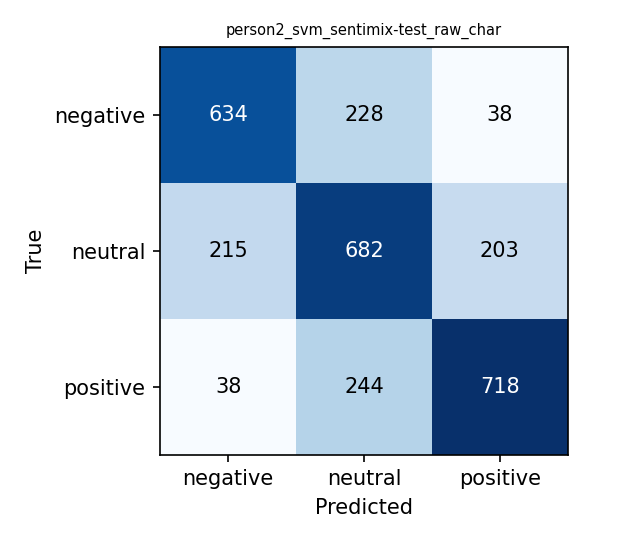

In [13]:
import sys; sys.path.insert(0, ".")
from src.evaluate import load_results
from IPython.display import Image, display
res = load_results()
display(res[["run_id", "dataset", "macro_f1", "accuracy", "f1_negative", "f1_neutral", "f1_positive"]].tail(4))
display(Image(f"results/confusion/{res.run_id.iloc[-1]}.png", width=380))

## 6. Optional: two more quick runs

* Character n-grams instead of words: `!python scripts/baseline_lr.py --owner $OWNER --features char`
* Tune C on validation, then test once: `!python scripts/baseline_lr.py --owner $OWNER --tune`

These are the first two of the six classical runs in the plan. To keep results, commit your `results/results_<you>.csv` and `results/preds/` files to the repo.